# A pre-registered test, scored reproducibly

A comparison is easiest to trust when the question, the unit of analysis, the statistic and the
rule that decides PASS or FAIL are written down before the data are looked at. This notebook
writes such a registration to a file, fingerprints it with SHA-256, then builds a synthetic size
distribution product with the package's own writer, computes the registered statistic and scores
it. Editing the rule afterwards changes the fingerprint, so a moved goalpost is visible.

It ends with a time-block train/test split, the leakage-safe way to divide per-second rows for a
benchmark. Worked on fixed-seed synthetic data.

**Before this:** [02_known_truth](02_known_truth.ipynb) (Checking against known truth). **Next:** [the examples index](../README.md). **Needs:** `pip install "arrayprobe[extra]"` (matplotlib).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/3_validation/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

## 1. Register the test before any data exist

The hypothesis: the second half of a 600 s period has a larger count-weighted mean diameter than
the first half. The unit is a 30 s block, so neighbouring seconds are not counted as independent
evidence. The statistic is the difference of the block-mean diameters (second half minus first),
in µm. The rule: PASS when the lower end of a 95 % block-bootstrap interval, with the seed and
resample count fixed here, is above 5 µm.

The registration is written as sorted JSON, so the same content always gives the same bytes and
the same hash.

In [2]:
import hashlib, json, tempfile

work = Path(tempfile.mkdtemp(prefix="nb38_"))

registration = {
    "hypothesis": "count-weighted mean diameter is larger in the second half of the period",
    "unit": "30 s block",
    "statistic": "mean over second-half blocks minus mean over first-half blocks, um",
    "pass_rule": "lower bound of 95 % block-bootstrap interval > threshold_um",
    "threshold_um": 5.0,
    "bootstrap": {"resamples": 2000, "seed": 2024, "level": 0.95},
}

def register(reg, path):
    text = json.dumps(reg, sort_keys=True, indent=1)
    path.write_text(text, encoding="utf-8")
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

reg_path = work / "registration.json"
reg_hash = register(registration, reg_path)
print(reg_path.name, "sha256:", reg_hash)

registration.json sha256: a00d352f8eb8709d446d2a0d7c67dda247a436e303f78c43da81658d82a44963


## 2. Build the data

A 600 s by 64-bin synthetic product of Poisson counts, written by the package's combined-product
writer and read back from the file, as a real product would be read. A small shift towards larger
sizes is put into the second half, so the test has something to find.

In [3]:
import numpy as np
import netCDF4
from arrayprobe import combine
from arrayprobe.matlab_compat import datenum

rng = np.random.default_rng(38)
N_TIME, N_BIN = 600, 64
edges = np.geomspace(0.01, 1.28, N_BIN + 1)                     # mm
mids = (edges[:-1] + edges[1:]) / 2
timevec = datenum(2020, 1, 1) + np.arange(N_TIME) / 86400.0
scale = np.where(np.arange(N_TIME) < N_TIME // 2, 15.0, 16.5)    # e-folding, in bins
mean_counts = 5.0 * np.exp(-np.arange(N_BIN)[None, :] / scale[:, None])
count = rng.poisson(mean_counts).astype(float)
nd = count / 1000.0
from arrayprobe_uiops.decode_naming import combined_name
source = work / combined_name("base200101000000", "H", "2DS", "3.5")
combine._write(source, 1, edges[:-1], edges[1:], mids, np.diff(edges), timevec,
               count * 0.01, count, nd, nd.sum(axis=1), nd.sum(axis=1) * 0.001)

with netCDF4.Dataset(source) as ds:
    counts = np.asarray(ds["Counts"][...]).T                     # (time, bin)
    mids_mm = np.asarray(ds["Bin Midpoints"][...])
print(source.name, counts.shape, f"{int(counts.sum())} particles")

base200101000000.combined.H.2DS.cdf (600, 64) 47931 particles


## 3. Compute the registered statistic

Each 30 s block gets one count-weighted mean diameter. The statistic is computed exactly as
registered; the bootstrap resamples blocks within each half, with the registered seed.

In [4]:
BLOCK = 30
blocks = counts.reshape(N_TIME // BLOCK, BLOCK, N_BIN).sum(axis=1)
dmean_um = (blocks * mids_mm).sum(axis=1) / blocks.sum(axis=1) * 1000.0
half = len(dmean_um) // 2
first, second = dmean_um[:half], dmean_um[half:]
stat = second.mean() - first.mean()

bs = registration["bootstrap"]
brng = np.random.default_rng(bs["seed"])
draws = np.array([
    brng.choice(second, second.size).mean() - brng.choice(first, first.size).mean()
    for _ in range(bs["resamples"])
])
lo, hi = np.quantile(draws, [(1 - bs["level"]) / 2, (1 + bs["level"]) / 2])
print(f"{len(dmean_um)} blocks; statistic = {stat:.2f} um, 95 % interval [{lo:.2f}, {hi:.2f}] um")

20 blocks; statistic = 7.20 um, 95 % interval [5.29, 9.13] um


This cell plots the test. On the left, the mean diameter of each 30 s block, split into the two halves being compared; on the right, the bootstrap draws of the statistic against the registered threshold and the lower end of the interval.

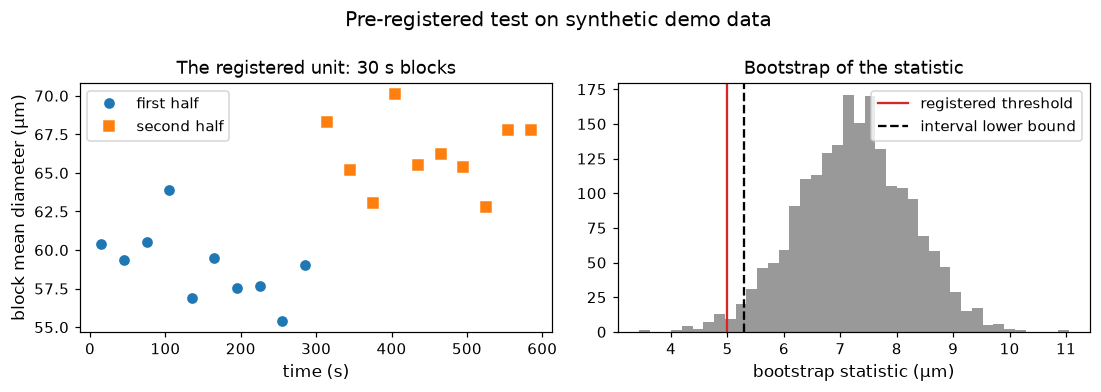

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
t_mid = (np.arange(len(dmean_um)) + 0.5) * BLOCK
axes[0].plot(t_mid[:half], first, "o", label="first half")
axes[0].plot(t_mid[half:], second, "s", label="second half")
axes[0].set_xlabel("time (s)")
axes[0].set_ylabel("block mean diameter (µm)")
axes[0].set_title("The registered unit: 30 s blocks")
axes[0].legend(fontsize=10)
axes[1].hist(draws, bins=40, color="0.6")
axes[1].axvline(registration["threshold_um"], color="C3", label="registered threshold")
axes[1].axvline(lo, color="k", ls="--", label="interval lower bound")
axes[1].set_xlabel("bootstrap statistic (µm)")
axes[1].set_title("Bootstrap of the statistic")
axes[1].legend(fontsize=10)
fig.suptitle("Pre-registered test on synthetic demo data")
fig.tight_layout()
plt.show()

*Figure 1. Pre-registered test on synthetic demo data. Left: the block mean diameter of each 30 s block, first and second half of the record. Right: the bootstrap distribution of the statistic, with the registered threshold and the interval lower bound.*

## 4. Score against the registration

The score reads the threshold from the file on disk, after checking that its hash is still the
one recorded before the data were built.

In [6]:
def score(path, expected_hash, lower_bound):
    text = path.read_text(encoding="utf-8")
    if hashlib.sha256(text.encode("utf-8")).hexdigest() != expected_hash:
        raise ValueError("registration changed after it was recorded")
    reg = json.loads(text)
    return "PASS" if lower_bound > reg["threshold_um"] else "FAIL"

print("registration hash:", reg_hash[:16], "...")
print(f"lower bound {lo:.2f} um vs threshold {registration['threshold_um']} um ->",
      score(reg_path, reg_hash, lo))

registration hash: a00d352f8eb8709d ...
lower bound 5.29 um vs threshold 5.0 um -> PASS


## 5. Moving the goalpost changes the hash

Suppose the threshold is edited after the result is known. The edited registration has a
different hash, so it cannot pass for the one recorded first, and scoring it against the recorded
hash refuses.

In [7]:
edited = dict(registration, threshold_um=round(float(lo) - 0.5, 1))
edited_path = work / "registration_edited.json"
edited_hash = register(edited, edited_path)
print("recorded:", reg_hash)
print("edited:  ", edited_hash)
print("same hash:", edited_hash == reg_hash)
try:
    score(edited_path, reg_hash, lo)
except ValueError as err:
    print("scoring the edited file against the recorded hash:", err)

recorded: a00d352f8eb8709d446d2a0d7c67dda247a436e303f78c43da81658d82a44963
edited:   2b7bd57820d78717ed498a340ef1cadc58ec6b7cb303df9a049942c6271b6bee
same hash: False
scoring the edited file against the recorded hash: registration changed after it was recorded


## 6. A leakage-safe train/test split

Neighbouring per-second rows are nearly copies of each other, so a random row split puts almost
the same second in both train and test. Splitting by whole 60 s blocks, and dropping a gap block
between train and test, keeps them apart. A fixed seed makes the split the same for everyone.

In [8]:
SPLIT_BLOCK = 60
block_id = np.arange(N_TIME) // SPLIT_BLOCK
n_blocks = block_id.max() + 1
srng = np.random.default_rng(7)
role = np.array(["train"] * n_blocks, dtype=object)
role[srng.choice(n_blocks, 3, replace=False)] = "test"
for b in range(n_blocks):          # a train block touching a test block becomes a gap
    if role[b] == "train" and any(0 <= b + d < n_blocks and role[b + d] == "test" for d in (-1, 1)):
        role[b] = "gap"
row_role = role[block_id]
seconds = np.arange(N_TIME)
train, test = seconds[row_role == "train"], seconds[row_role == "test"]
nearest = np.min(np.abs(test[:, None] - train[None, :]))
print("blocks:", " ".join(f"{b}:{r}" for b, r in enumerate(role)))
print(f"train {train.size} s, test {test.size} s, closest train-test pair {nearest} s apart")

random_rows = np.random.default_rng(7).permutation(N_TIME)
r_test, r_train = np.sort(random_rows[:180]), np.sort(random_rows[180:])
r_near = np.min(np.abs(r_test[:, None] - r_train[None, :]))
print(f"random row split for comparison: closest train-test pair {r_near} s apart")

blocks: 0:train 1:train 2:train 3:train 4:gap 5:test 6:test 7:test 8:gap 9:train
train 300 s, test 180 s, closest train-test pair 61 s apart
random row split for comparison: closest train-test pair 1 s apart


## Summary

- The hypothesis, unit, statistic and PASS rule are written to a file and hashed before the data
  are built.
- The statistic is computed exactly as registered, and the score checks the hash first.
- Changing the rule afterwards changes the hash, so the change shows.
- Splitting by time blocks with a gap keeps neighbouring seconds out of both train and test.